# Compiling a piecewise linear function

Turn a table of knots and heights into the weights of a rectifier network.

Start with the first segment slope. At each interior knot, add a hinge with a weight equal to the change in slope. A skip connection carries the initial straight line. Endpoint extrapolation follows the first and last slopes.

In [1]:
import numpy as np
import matplotlib.pyplot as plt

## Construct the weights and test their behaviour

Inspect the arrays and the reference output. Each check describes a specific property of the constructed model.

slope changes [-2.06   2.778 -1.889] maximum grid error 9.44e-16


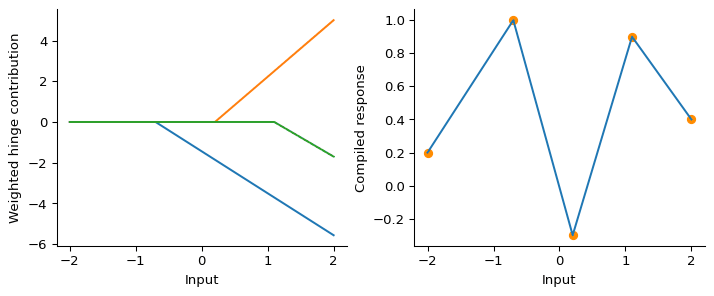

In [2]:
knots = np.array([-2.0, -0.7, 0.2, 1.1, 2.0])
values = np.array([0.2, 1.0, -0.3, 0.9, 0.4])
slopes = np.diff(values) / np.diff(knots)
jumps = np.diff(slopes)
x = np.linspace(knots[0], knots[-1], 401)
features = np.maximum(0, x[:, None] - knots[None, 1:-1])
output = values[0] + slopes[0] * (x - knots[0]) + features @ jumps
ref = np.interp(x, knots, values)
print("slope changes", jumps.round(3), "maximum grid error", f"{abs(ref-output).max():.2e}")
assert np.allclose(output, ref)
fig, (a, b) = plt.subplots(1, 2, figsize=(7.4, 3), constrained_layout=True)
a.plot(x, features * jumps)
a.set(xlabel="Input", ylabel="Weighted hinge contribution")
b.plot(x, output)
b.scatter(knots, values, color="darkorange")
b.set(xlabel="Input", ylabel="Compiled response")
plt.show()

## Interpreting the result

The location of a kink is a bias. Its signed change of slope is an output weight. Both can be edited independently.

## Exercise

Insert one extra knot on a straight segment and predict the added weight.

## References

[Unser, a representer theorem for deep neural networks (2019)](https://www.jmlr.org/papers/v20/18-418.html)

[WeightCode, weight-space programming preprint (2026)](https://arxiv.org/abs/2611.25476)